In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score



In [43]:
df = pd.read_csv(r"C:\Users\ugniu\PycharmProjects\Unsupervised  learning\Data\Processed\mental_health_cleaned.csv")

In [29]:
X = df.copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA()
pca.fit(X_scaled)

cumulative_variance = pca.explained_variance_ratio_.cumsum()

for i, variance in enumerate(cumulative_variance, start=1):
    print(i, variance)

1 0.0677439042897766
2 0.12122099886300074
3 0.16719817461189004
4 0.20350328051468244
5 0.23146655728319074
6 0.25474864220173
7 0.2756317587195922
8 0.2958163651279426
9 0.31497081296546364
10 0.332336279650541
11 0.34881519313618403
12 0.36453429864593734
13 0.3794978436569949
14 0.3938584255959813
15 0.4076318682559266
16 0.4209699021411709
17 0.4342347260039849
18 0.4471190506894977
19 0.459837831546819
20 0.4723178456818824
21 0.48476472890324757
22 0.4968370767511021
23 0.508714772158468
24 0.5203779245923364
25 0.5318849044253029
26 0.5430346917935255
27 0.5541244146826255
28 0.5650086548764778
29 0.5757619810654739
30 0.586325304656156
31 0.5967355841056426
32 0.6070732337344745
33 0.6172985663909183
34 0.6272730464388765
35 0.6371778746192618
36 0.6469645682556341
37 0.6565528090544976
38 0.6661005341857705
39 0.6755581057007375
40 0.6848298518383747
41 0.6940392110280985
42 0.703183147406396
43 0.7121276679347632
44 0.7210185207769986
45 0.7297611341309392
46 0.7383933232588

In [30]:
for n_comp in [3,4 , 5, 6, 7, 8,9,10]:
    pca = PCA(n_components=n_comp, random_state=42)
    X_pca = pca.fit_transform(X_scaled)
    best_sil, best_k = -1, None
    for k in range(2, 9):
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = km.fit_predict(X_pca)
        sil = silhouette_score(X_pca, labels)
        if sil > best_sil:
            best_sil, best_k = sil, k
    print(f"n_components={n_comp:4d} | variance={pca.explained_variance_ratio_.sum():.3f} | best k={best_k} | best silhouette={best_sil:.4f}")

n_components=   3 | variance=0.167 | best k=4 | best silhouette=0.3334
n_components=   4 | variance=0.204 | best k=3 | best silhouette=0.2794
n_components=   5 | variance=0.231 | best k=3 | best silhouette=0.2533
n_components=   6 | variance=0.255 | best k=3 | best silhouette=0.2291
n_components=   7 | variance=0.276 | best k=3 | best silhouette=0.2119
n_components=   8 | variance=0.296 | best k=3 | best silhouette=0.1967
n_components=   9 | variance=0.315 | best k=3 | best silhouette=0.1835
n_components=  10 | variance=0.332 | best k=3 | best silhouette=0.1749


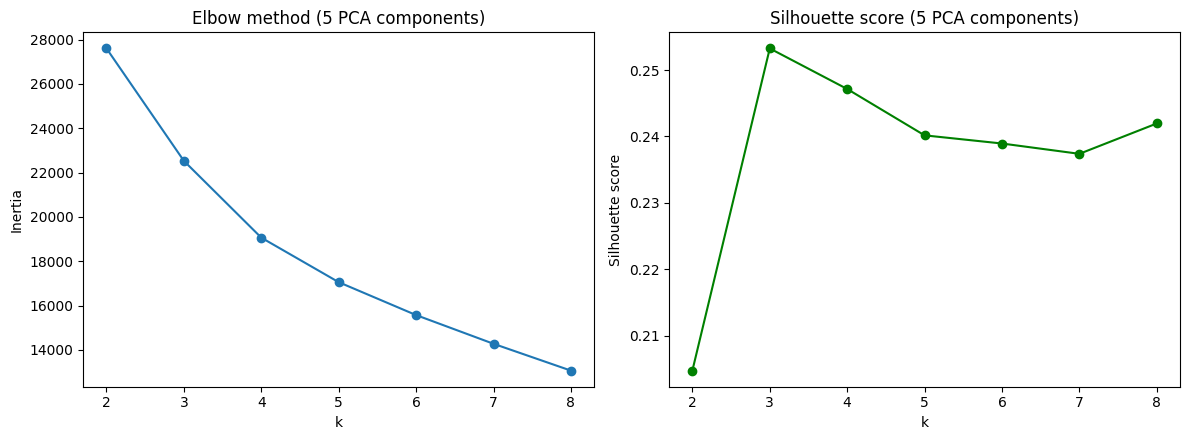

k=2: inertia=27597.8, silhouette=0.2047
k=3: inertia=22525.2, silhouette=0.2533
k=4: inertia=19061.8, silhouette=0.2471
k=5: inertia=17054.2, silhouette=0.2402
k=6: inertia=15569.9, silhouette=0.2389
k=7: inertia=14275.1, silhouette=0.2374
k=8: inertia=13064.8, silhouette=0.2419


In [31]:


pca = PCA(n_components=5, random_state=42)
X_pca = pca.fit_transform(X_scaled)

k_range = range(2, 9)
inertias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_pca)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_pca, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(list(k_range), inertias, marker='o')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow method (5 PCA components)')

axes[1].plot(list(k_range), silhouettes, marker='o', color='green')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette score (5 PCA components)')

plt.tight_layout()
plt.show()

for k, inertia, sil in zip(k_range, inertias, silhouettes):
    print(f"k={k}: inertia={inertia:.1f}, silhouette={sil:.4f}")

In [32]:
# PCA loadings
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(5)],
    index=X.columns
)

# Show the 10 variables with the strongest loadings
# for each principal component
for pc in loadings.columns:
    print(f"\n===== {pc} =====")

    top_loadings = loadings[pc].sort_values(
        key=abs,
        ascending=False
    ).head(10)

    print(top_loadings)


===== PC1 =====
Do you currently have a mental health disorder?                                                                         0.283173
If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?    0.273562
Have you been diagnosed with a mental health condition by a medical professional?                                       0.268874
Have you had a mental health disorder in the past?                                                                      0.268640
Have you ever sought treatment for a mental health issue from a mental health professional?                             0.259243
condition_Mood Disorder                                                                                                 0.237836
If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?        0.216360
condition_Anxiety                                                               

cluster
0    547
1    595
2    286
Name: count, dtype: int64


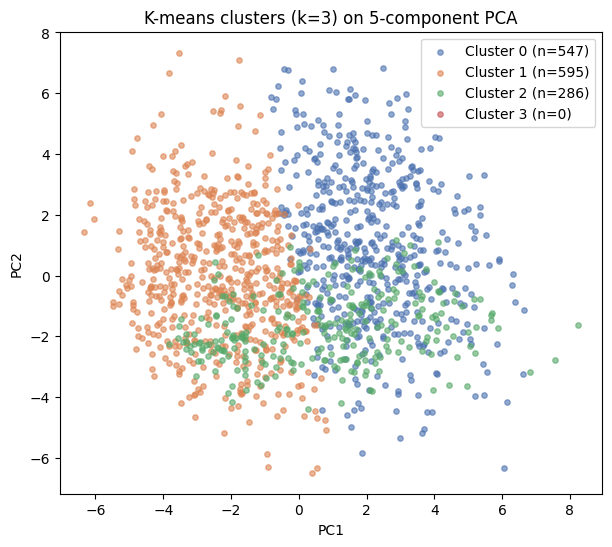

In [33]:

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_pca)

df["cluster"] = cluster_labels
print(df["cluster"].value_counts().sort_index())

colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']  # 4 colors now, properly quoted
plt.figure(figsize=(7, 6))
for c in range(4):  # loop through all 4 clusters
    mask = cluster_labels == c
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], s=15, alpha=0.6, label=f'Cluster {c} (n={mask.sum()})', color=colors[c])
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('K-means clusters (k=3) on 5-component PCA')
plt.legend()
plt.show()



In [34]:
for seed in [0, 42, 123,1000,15,38]:
    km = KMeans(n_clusters=3, random_state=seed, n_init=10)
    labels = km.fit_predict(X_pca)
    sizes = pd.Series(labels).value_counts().sort_index().tolist()
    sil = silhouette_score(X_pca, labels)
    print(f"seed={seed}: sizes={sizes}, silhouette={sil:.4f}")

seed=0: sizes=[595, 547, 286], silhouette=0.2533
seed=42: sizes=[547, 595, 286], silhouette=0.2533
seed=123: sizes=[595, 286, 547], silhouette=0.2533
seed=1000: sizes=[547, 286, 595], silhouette=0.2533
seed=15: sizes=[595, 286, 547], silhouette=0.2533
seed=38: sizes=[285, 597, 546], silhouette=0.2534


In [35]:
key_vars = [
    "Are you self-employed?",
    "Have you been diagnosed with a mental health condition by a medical professional?",
    "Have you ever sought treatment for a mental health issue from a mental health professional?",
    "What is your age?",
    "Do you work remotely?",
]

summary = df.groupby("cluster")[key_vars].mean().round(2)
summary["N"] = df["cluster"].value_counts().sort_index()
summary["% of sample"] = (summary["N"] / len(df) * 100).round(1)
print(summary)
print()

# Gender composition per cluster
gender_cols = [c for c in df.columns if c.startswith("gender_")]
print((df.groupby("cluster")[gender_cols].mean() * 100).round(1))
print()

# Top conditions per cluster
condition_cols = [c for c in df.columns if c.startswith("condition_")]
cond_summary = (df.groupby("cluster")[condition_cols].mean() * 100).round(1).T
cond_summary["overall_avg"] = cond_summary.mean(axis=1)
print(cond_summary.sort_values("overall_avg", ascending=False).drop(columns="overall_avg").head(6))
print()

# Top roles per cluster
role_cols = [c for c in df.columns if c.startswith("role_")]
role_summary = (df.groupby("cluster")[role_cols].mean() * 100).round(1).T
role_summary["overall_avg"] = role_summary.mean(axis=1)
print(role_summary.sort_values("overall_avg", ascending=False).drop(columns="overall_avg").head(5))

         Are you self-employed?  \
cluster                           
0                           0.0   
1                           0.0   
2                           1.0   

         Have you been diagnosed with a mental health condition by a medical professional?  \
cluster                                                                                      
0                                                     0.88                                   
1                                                     0.14                                   
2                                                     0.52                                   

         Have you ever sought treatment for a mental health issue from a mental health professional?  \
cluster                                                                                                
0                                                     0.93                                             
1                                        

In [36]:
cluster_profile = df.groupby("cluster").mean(numeric_only=True).T

cluster_profile["range"] = (
    cluster_profile.max(axis=1)
    - cluster_profile.min(axis=1)
)

cluster_profile.sort_values(
    "range",
    ascending=False
).head(30)

cluster,0,1,2,range
What is your age?,33.976234,32.825210,36.919580,4.094370
"If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?",2.583181,0.778151,1.779720,1.805030
Do you currently have a mental health disorder?,1.694698,0.383193,1.115385,1.311505
Have you had a mental health disorder in the past?,1.820841,0.588235,1.286713,1.232606
Are you self-employed?,0.001828,0.000000,0.996503,0.996503
"If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?",1.354662,0.366387,1.027972,0.988275
is_tech_comp?_1.0,0.764168,0.774790,0.000000,0.774790
discussing_physical_employer_ordinal,1.376600,1.242017,2.000000,0.757983
Have you been diagnosed with a mental health condition by a medical professional?,0.879342,0.141176,0.520979,0.738165
healthcare_employer_discussion_No,0.714808,0.705882,0.000000,0.714808


In [37]:
summary = df.groupby("cluster")[[
    "Are you self-employed?",
    "Have you been diagnosed with a mental health condition by a medical professional?",
    "Have you ever sought treatment for a mental health issue from a mental health professional?",
    "What is your age?",
]].mean().round(2)

summary.columns = ["Self-employed", "Diagnosed", "Sought treatment", "Avg age"]
summary["Number of people"] = df["cluster"].value_counts().sort_index()
summary["% of sample"] = (summary["Number of people"] / len(df) * 100).round(1)
print(summary)

         Self-employed  Diagnosed  Sought treatment  Avg age  \
cluster                                                        
0                  0.0       0.88              0.93    33.98   
1                  0.0       0.14              0.24    32.83   
2                  1.0       0.52              0.64    36.92   

         Number of people  % of sample  
cluster                                 
0                     547         38.3  
1                     595         41.7  
2                     286         20.0  


In [38]:
df.groupby("cluster")["Do you have a family history of mental illness?"].mean().mul(100).plot(kind="bar", ax=axes[1,0], color=colors)
axes[1,0].set_title("% MH family history")

plt.tight_layout()
plt.show()

IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

In [53]:
print("Number of variables:", X.shape[1])

for col in X.columns:
    print(col)

Number of variables: 106
Are you self-employed?
Have you heard of or observed negative consequences for co-workers who have been open about mental health issues in your workplace?
Do you have previous employers?
Have your previous employers provided mental health benefits?
Were you aware of the options for mental health care provided by your previous employers?
Did your previous employers ever formally discuss mental health (as part of a wellness campaign or other official communication)?
Did your previous employers provide resources to learn more about mental health issues and how to seek help?
Was your anonymity protected if you chose to take advantage of mental health or substance abuse treatment resources with previous employers?
Do you think that discussing a mental health disorder with previous employers would have negative consequences?
Do you think that discussing a physical health issue with previous employers would have negative consequences?
Would you have been willing to di

In [40]:
import pandas as pd
import numpy as np
import gower

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

X = df.copy()

# Gower distance
D = gower.gower_matrix(X)

results = []

for k in range(2, 9):

    model = AgglomerativeClustering(
        n_clusters=k,
        metric="precomputed",
        linkage="average"
    )

    labels = model.fit_predict(D)

    silhouette = silhouette_score(
        D,
        labels,
        metric="precomputed"
    )

    results.append({
        "k": k,
        "silhouette": silhouette
    })

results = pd.DataFrame(results)

print(results)

   k  silhouette
0  2    0.203600
1  3    0.149083
2  4    0.120197
3  5    0.098282
4  6    0.071372
5  7    0.047944
6  8    0.036901
